<a href="https://colab.research.google.com/github/eddybanshuy/proyectoF_MAP/blob/main/Proyecto_MAP_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="width: 100%; clear: both;">
<div style="float: left; width: 30%;">
<img src="https://utpl.edu.ec/recursos/img/utpl2.png", align="left" width="280" height="120">
</div>
</div>
<div style="float: right; width: 70%;">
<p style="margin: 0; padding-top: 32px; text-align:right; color:#003366; font-size:16px"><u>Metodos de Aprendizaje Profundo</u></p>
<p style="margin: 0; text-align:right; color:#999999; font-size:17px">Maestría en Inteligencia Artificial Aplicada</p>
<p style="margin: 0; text-align:right; color:#999999; font-size:17px">Maestrante Edison Banshuy, Gladys Sanchez </p>
</div>
</div>
<div style="width: 100%; clear: both;">
<div style="width:100%;">&nbsp;</div>

**Planteamiento de la actividad**

Estimados maestrantes,

A continuación, se detalla la actividad correspondiente al proyecto bimestral de la asignatura de Aprendizaje Profundo. El objetivo es que implementen una arquitectura de reconocimiento facial utilizando un conjunto de datos pre-entrenados, aplicando técnicas de visión por computador y aprendizaje profundo.



1.   **Descripción general de la actividad**

El proyecto consiste en desarrollar un prototipo funcional de reconocimiento facial que sea capaz de identificar rostros a partir de un conjunto de datos base (imágenes faciales de cada estudiante del curso) al que deberán agregar nuevas muestras. El modelo se entrenará (técnica fine-tuning) con dichas imágenes y se evaluará tanto en imágenes estáticas como en video. Para ello, emplearán las librerías dlib y face_recognition en un entorno de desarrollo como Google Colab o Anaconda.

2.   **Conformación de equipos y metodología de trabajo**

Los grupos serán de dos estudiantes.



  * Realizar la revisión sistemática de la literatura consultando al menos cuatro artículos científicos indexados en bases como IEEE Xplore, Springer, ScienceDirect, ACM, entre otras.
  * La revisión debe abordar: propiedades, características, funcionamiento y metodologías para desarrollar sistemas de reconocimiento facial.

  * Se recomienda utilizar la plataforma Google Colab (por su facilidad para trabajar con GPUs) o el software Anaconda (para entornos locales).

  * Revisar el tutorial de Face Recognition proporcionado por el docente. A partir de este, agregarán nuevas imágenes al conjunto de datos base (imágenes de cada integrante del grupo y, opcionalmente, de otros compañeros) para reentrenar o ajustar el modelo.

  * La fase de experimentación y análisis de resultados tiene que probarse con imágenes fijas y con secuencias de video. El prototipo final debe identificar correctamente los rostros incluidos en su conjunto de datos, mostrando la información asociada (nombre, código, etc.).

Descargar el proyecto base donde se proporciona el código fuente e imágenes.



# Dependencias

En el siguiente paso instalamos todas las dependencias necesarias para la realizacion del proyecto de reconocimiento facial.

In [1]:
#Librerias necesarias

!pip install face-recognition imutils

# Actualizar e instalar dependencias del sistema para dlib
!apt-get update -y

!apt-get install -y cmake libboost-all-dev libopenblas-dev liblapack-dev

# Instalar librerias de Python
!pip install dlib
!pip install face_recognition
!pip install imutils
!pip install opencv-python-headless

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 56.2 MB/s  0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=0b9b90b011335be42a820a31c2aa7536f860d8f35b0ba25c8c58e08938261d44
  Stored in directory: /root/.cache/pip/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [face-recognition]
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,510 kB]
Get:6 http://security.u

# Librerias

En el siguiente paso importamos las librerias

In [2]:
# Importamos los paquetes necesarios

import imutils
import face_recognition
import argparse
import pickle
import cv2
import os
import dlib
import matplotlib.pyplot as plt
import subprocess
import pandas as pd
import gc
import numpy as np
import time


from matplotlib.patches import Patch
from base64 import b64encode
from IPython.display import display, HTML
from google.colab import files
from imutils import paths
from google.colab.patches import cv2_imshow
from google.colab import drive




# Verificar si dlib está compilado con soporte para CUDA/GPU
print("¿Dlib está usando CUDA?:", dlib.DLIB_USE_CUDA)

# Parche necesario para mostrar imagenes en Colab
from google.colab.patches import cv2_imshow

/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


¿Dlib está usando CUDA?: False


# Google Drive
En esta sesion conectare mi google drive para la utilizacion de la dataset de los diferentes personajes.

Tambien la ruta donde voy a guardar el **encodings.pickle** y tambien la ruta de un nuevo directorio donde contego imagenes para comprobar si el modelo funciona al reconocer el personaje.

In [12]:
# Montar Drive si aún no está montado
#if not os.path.exists('/content/drive'):
#    drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv'
DATASET_PATH = os.path.join(BASE_DIR, 'dataset')
ENCODINGS_PATH = os.path.join(DATASET_PATH, 'encodings.pickle')
TEST_PATH = os.path.join(BASE_DIR, 'reconocer')

# Resumen de imagenes por clase
datos = [
    {
        "Personaje": p,
        "Imagenes": len([
            f for f in os.listdir(os.path.join(DATASET_PATH, p))
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
    }
    for p in sorted(os.listdir(DATASET_PATH))
    if os.path.isdir(os.path.join(DATASET_PATH, p)) and not p.startswith(".")
]

df_resumen = pd.DataFrame(datos).sort_values(by="Imagenes", ascending=False).reset_index(drop=True)
display(df_resumen)

,Personaje,Imagenes
0,claire_dearing,53
1,gladys,41
2,ian_malcolm,41
3,eddy,40
4,john_hammond,36
5,owen_grady,35
6,ellie_sattler,31
7,alan_grant,22


Como resultado tenemos los dataset de los diferentes personajes mas los agregados que en este caso es **eddy y gladys**, tambien podremos observar que tenemos el numero de imagenes.

# Preparacion del dataset

En este apartado vamos a realizar una exploracion de los dataset si estan optimos para el proceso de reconocimiento facial

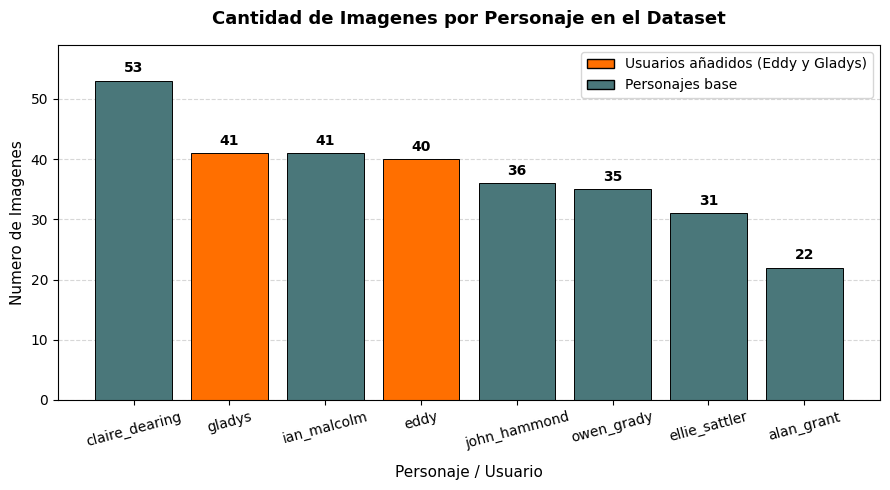

In [13]:
# En este apartado defino los usuarios a resaltar
usuarios_destacados = {'eddy', 'gladys'}

# Asigno naranja para usuarios personalizados y azul para el dataset base
colores = [
    '#FF6F00' if p.lower() in usuarios_destacados else '#4A777A'
    for p in df_resumen['Personaje']
]

# Creo la figura
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(df_resumen['Personaje'], df_resumen['Imagenes'], color=colores, edgecolor='black', linewidth=0.7)

# Añadir el numero exacto encima de cada barra
for barra in barras:
    altura = barra.get_height()
    ax.annotate(
        f'{int(altura)}',
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),  # Desplazamiento vertical en puntos
        textcoords="offset points",
        ha='center', va='bottom',
        fontsize=10, fontweight='bold'
    )

# Titulos, etiquetas y estilo
ax.set_title('Cantidad de Imagenes por Personaje en el Dataset', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Personaje / Usuario', fontsize=11, labelpad=10)
ax.set_ylabel('Numero de Imagenes', fontsize=11)
ax.set_ylim(0, df_resumen['Imagenes'].max() + 6)  # Espacio superior para que no se corte el numero
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

# Leyenda personalizada
leyenda = [
    Patch(facecolor='#FF6F00', edgecolor='black', label='Usuarios añadidos (Eddy y Gladys)'),
    Patch(facecolor='#4A777A', edgecolor='black', label='Personajes base')
]
ax.legend(handles=leyenda, loc='upper right', frameon=True)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Como podremos observar en la imagen de barras, tenemos a los ferentes personajes de los dataset y los usuarios incluidos los cuales estan de otro color, asi mismo tenemos el numero de imagenes que tiene cada personaje.

**Promedio de imagenes**

En el siguiente apartado, se codifica un algoritmo el cual me ayude a calcular cual el promedio de imagenes que se necesita para realizar un buen entrenamiento del modelo de reconocimiento facial.

,Personaje,Imagenes,Meta_Sugerida,Faltantes,Estado
0,claire_dearing,53,38,0,Optimo
1,gladys,41,38,0,Optimo
2,ian_malcolm,41,38,0,Optimo
3,eddy,40,38,0,Optimo
4,john_hammond,36,38,2,Aceptable (Faltan 2)
5,owen_grady,35,38,3,Aceptable (Faltan 3)
6,ellie_sattler,31,38,7,Deficit (Faltan ~7)
7,alan_grant,22,38,16,Deficit (Faltan ~16)


RECOMENDACIONES DEL SISTEMA 
Se detecto desbalanceo en 4 clase(s) por debajo de la meta (38 imagenes):
   - john_hammond: tiene 36 imagenes -> Agrega al menos 2 mas.
   - owen_grady: tiene 35 imagenes -> Agrega al menos 3 mas.
   - ellie_sattler: tiene 31 imagenes -> Agrega al menos 7 mas.
   - alan_grant: tiene 22 imagenes -> Agrega al menos 16 mas.
Nota tecnica: 'claire_dearing' (53) tiene mas del 60% de muestras extra que 'alan_grant' (22).
Para evitar sesgos al clasificar, usa 'face_distance' (distancia minima) en lugar de votacion simple.


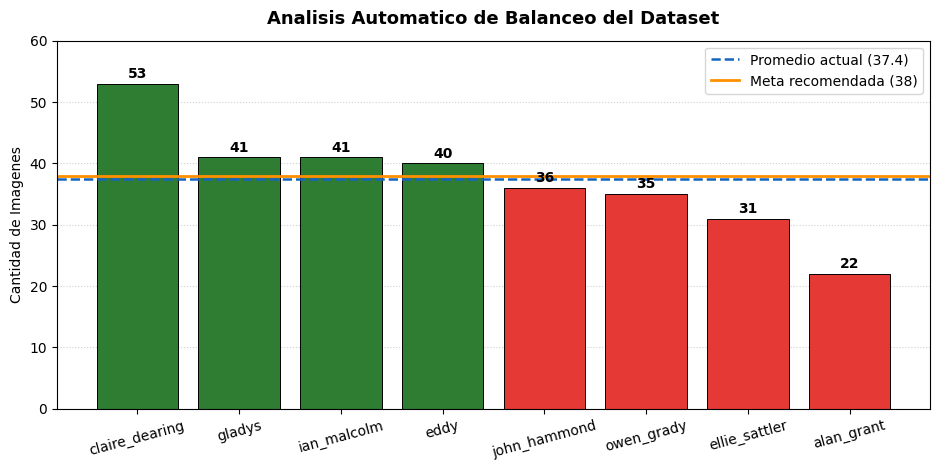

In [19]:

# Algoritmo para sacar el promedio de imagenes
DATASET_PATH = '/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/dataset'

def analizar_y_recomendar_dataset(ruta_dataset, piso_minimo_ideal=30):
    if not os.path.exists(ruta_dataset):
        print(f"[ERROR] No se encontro la ruta: {ruta_dataset}")
        return

    # Leer automaticamente las carpetas y contar imagenes validas
    extensiones_validas = ('.jpg', '.jpeg', '.png')
    registros = []

    for carpeta in sorted(os.listdir(ruta_dataset)):
        ruta_clase = os.path.join(ruta_dataset, carpeta)
        if os.path.isdir(ruta_clase) and not carpeta.startswith('.'):
            cantidad = len([
                f for f in os.listdir(ruta_clase)
                if f.lower().endswith(extensiones_validas)
            ])
            registros.append({'Personaje': carpeta, 'Imagenes': cantidad})

    if not registros:
        print("[ALERTA] No se encontraron carpetas con imagenes en el dataset.")
        return

    df = pd.DataFrame(registros).sort_values(by='Imagenes', ascending=False).reset_index(drop=True)

    # Calculos estadisticos
    total_imagenes = df['Imagenes'].sum()
    promedio = df['Imagenes'].mean()
    desviacion = df['Imagenes'].std()
    max_imgs = df['Imagenes'].max()
    min_imgs = df['Imagenes'].min()

    # Meta: tomar el mayor valor entre el promedio actual redondeado o el piso minimo ideal
    meta_objetivo = max(int(np.ceil(promedio)), piso_minimo_ideal)

    # Evaluar estado por personaje
    def evaluar_clase(cant):
        if cant < meta_objetivo * 0.85:
            return f"Deficit (Faltan ~{meta_objetivo - cant})"
        elif cant < meta_objetivo:
            return f"Aceptable (Faltan {meta_objetivo - cant})"
        else:
            return "Optimo"

    df['Meta_Sugerida'] = meta_objetivo
    df['Faltantes'] = np.maximum(0, meta_objetivo - df['Imagenes'])
    df['Estado'] = df['Imagenes'].apply(evaluar_clase)

    # Reporte automatico y recomendaciones


    display(df[['Personaje', 'Imagenes', 'Meta_Sugerida', 'Faltantes', 'Estado']])

    print("RECOMENDACIONES DEL SISTEMA ")
    clases_bajas = df[df['Faltantes'] > 0]

    if clases_bajas.empty:
        print("¡Excelente! Todas las clases cumplen o superan la meta recomendada. El dataset esta bien balanceado.")
    else:
        print(f"Se detecto desbalanceo en {len(clases_bajas)} clase(s) por debajo de la meta ({meta_objetivo} imagenes):")
        for _, fila in clases_bajas.iterrows():
            print(f"   - {fila['Personaje']}: tiene {fila['Imagenes']} imagenes -> Agrega al menos {fila['Faltantes']} mas.")

    if max_imgs > min_imgs * 1.6:
        clase_mayor = df.iloc[0]['Personaje']
        clase_menor = df.iloc[-1]['Personaje']
        print(f"Nota tecnica: '{clase_mayor}' ({max_imgs}) tiene mas del 60% de muestras extra que '{clase_menor}' ({min_imgs}).")
        print("Para evitar sesgos al clasificar, usa 'face_distance' (distancia minima) en lugar de votacion simple.")



        # Grafico  del diagnóstico
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    colores = ['#E53935' if f > 0 else '#2E7D32' for f in df['Faltantes']]

    barras = ax.bar(df['Personaje'], df['Imagenes'], color=colores, edgecolor='black', linewidth=0.7)
    ax.axhline(promedio, color='#1565C0', linestyle='--', linewidth=1.8, label=f'Promedio actual ({promedio:.1f})')
    ax.axhline(meta_objetivo, color='#FF8F00', linestyle='-', linewidth=2, label=f'Meta recomendada ({meta_objetivo})')

    for barra in barras:
        h = barra.get_height()
        ax.annotate(f'{int(h)}', xy=(barra.get_x() + barra.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points", ha='center', fontweight='bold')

    ax.set_title('Analisis Automatico de Balanceo del Dataset', fontsize=13, fontweight='bold', pad=12)
    ax.set_ylabel('Cantidad de Imagenes')
    ax.set_ylim(0, max_imgs + 7)
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.set_axisbelow(True)

    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

# Ejecutar analisis
analizar_y_recomendar_dataset(DATASET_PATH)



Como podemos los personajes objetivos a reconocer estan por encima del promedio

# Encode Face

En este apartado se codifica las imagenes, el cual nos da como resulatado el archivo **encodigs.pickle**, servira para la deteccion del los rostros.

En este caso utilizamos el modelo **" HOG "** ya que nos permite trabajar en la plataforma de google colab. Por los recursos limitados que se tiene en maquina por lo cual se evito trabajar con el modelo **" CNN "**.

In [20]:
def generar_encodings(dataset_dir, output_pickle, model="hog", max_width=800):
    print(f"[INFO] Iniciando extraccion de encodings (modelo: {model})...")
    image_paths = list(paths.list_images(dataset_dir))
    known_encodings = []
    known_names = []
    omitidas = 0

    for i, image_path in enumerate(image_paths):
        name = os.path.basename(os.path.dirname(image_path))
        image = cv2.imread(image_path)

        if image is None:
            print(f"[ADVERTENCIA] No se pudo leer: {image_path}")
            omitidas += 1
            continue

        # Redimensionar para optimizar memoria y velocidad
        if image.shape[1] > max_width:
            image = imutils.resize(image, width=max_width)

        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        boxes = face_recognition.face_locations(rgb, model=model)
        encodings = face_recognition.face_encodings(rgb, boxes)

        for encoding in encodings:
            known_encodings.append(encoding)
            known_names.append(name)

        if (i + 1) % 25 == 0 or (i + 1) == len(image_paths):
            print(f"[INFO] Procesadas {i + 1}/{len(image_paths)} imágenes...")
            gc.collect()

    data = {"encodings": known_encodings, "names": known_names}
    with open(output_pickle, "wb") as f:
        pickle.dump(data, f)

    print(f"[INFO] Guardados {len(known_encodings)} rostros en {output_pickle}. Imagenes omitidas: {omitidas}.")

# Ejecutar extraccion (cambiar a model="cnn" si DLIB_USE_CUDA es True)
generar_encodings(DATASET_PATH, ENCODINGS_PATH, model="hog")

[INFO] Iniciando extraccion de encodings (modelo: hog)...
[INFO] Procesadas 25/299 imágenes...
[INFO] Procesadas 50/299 imágenes...
[INFO] Procesadas 75/299 imágenes...
[INFO] Procesadas 100/299 imágenes...
[INFO] Procesadas 125/299 imágenes...
[INFO] Procesadas 150/299 imágenes...
[INFO] Procesadas 175/299 imágenes...
[INFO] Procesadas 200/299 imágenes...
[INFO] Procesadas 225/299 imágenes...
[INFO] Procesadas 250/299 imágenes...
[INFO] Procesadas 275/299 imágenes...
[INFO] Procesadas 299/299 imágenes...
[INFO] Guardados 232 rostros en /content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/dataset/encodings.pickle. Imagenes omitidas: 0.


Como resultado tenemos las imagenes procesadas y guardadas en nuestro Google Drive, el cual nos servira despues para realizar los procesos de reconocimiento. Debido a la demora de codificacion de las mismas se obto por guardar el archivo en la nube.

**Prueba**

En este apartado realizo una prueba con un directorio nuevo que agrege con los diferentes tipos de imagenes tomadas al alzar de los diferentes personajes a tratar.

[INFO] Analizando 44 imagenes de prueba...


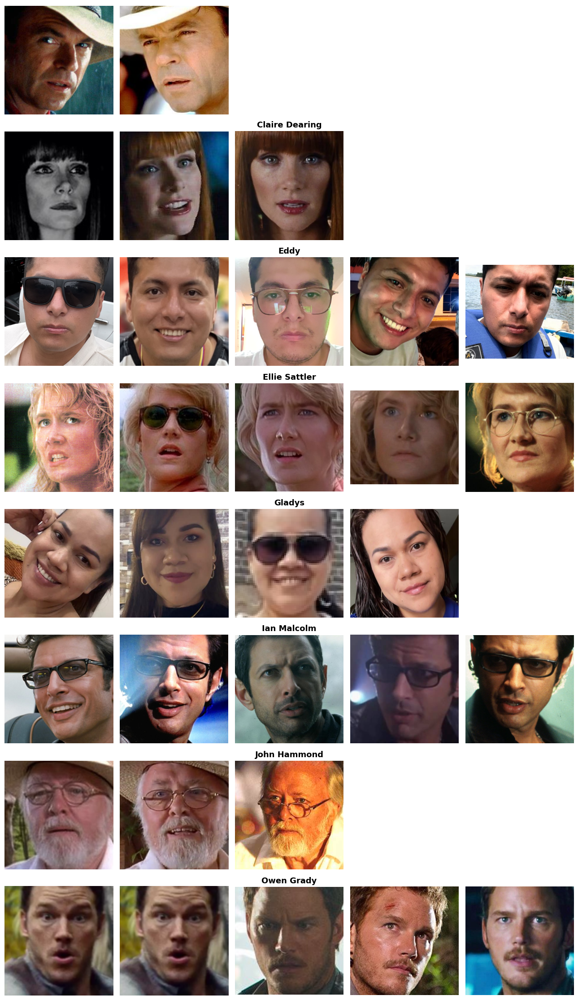

In [21]:

def reconocer_y_graficar(encodings_path, test_dir, tolerance=0.5, max_imagenes=5, padding_ratio=0.15):
    with open(encodings_path, "rb") as f:
        data = pickle.load(f)

    known_encodings = np.array(data["encodings"])
    known_names = np.array(data["names"])
    image_paths = list(paths.list_images(test_dir))

    rostros_por_autor = {}
    print(f"[INFO] Analizando {len(image_paths)} imagenes de prueba...")

    for image_path in image_paths:
        image = cv2.imread(image_path)
        if image is None:
            continue

        if image.shape[1] > 1000:
            image = imutils.resize(image, width=1000)

        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h_img, w_img, _ = rgb.shape

        boxes = face_recognition.face_locations(rgb, model="hog")
        encodings = face_recognition.face_encodings(rgb, boxes)

        for (top, right, bottom, left), encoding in zip(boxes, encodings):
            # Calcular distancias euclidianas contra todos los encodings conocidos
            distances = face_recognition.face_distance(known_encodings, encoding)
            best_match_idx = np.argmin(distances)

            if distances[best_match_idx] <= tolerance:
                name = known_names[best_match_idx]
            else:
                name = "Desconocido"

            if name != "Desconocido":
                rostros_por_autor.setdefault(name, [])

                if len(rostros_por_autor[name]) < max_imagenes:
                    # Calcular margen alrededor del rostro
                    pad_h = int((bottom - top) * padding_ratio)
                    pad_w = int((right - left) * padding_ratio)

                    y1 = max(0, top - pad_h)
                    y2 = min(h_img, bottom + pad_h)
                    x1 = max(0, left - pad_w)
                    x2 = min(w_img, right + pad_w)

                    rostro_recortado = rgb[y1:y2, x1:x2]
                    rostros_por_autor[name].append((rostro_recortado, distances[best_match_idx]))

    # Visualización en cuadricula
    num_autores = len(rostros_por_autor)
    if num_autores == 0:
        print("[ALERTA] No se reconocio a ningun personaje dentro del umbral establecido.")
        return

    fig, axes = plt.subplots(nrows=num_autores, ncols=max_imagenes, figsize=(13, 2.8 * num_autores))
    if num_autores == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, (autor, items) in enumerate(sorted(rostros_por_autor.items())):
        for j in range(max_imagenes):
            ax = axes[i, j]
            ax.axis("off")

            if j < len(items):
                rostro, dist = items[j]
                ax.imshow(rostro)
                ax.set_xlabel(f"Dist: {dist:.2f}", fontsize=9)
                if j == max_imagenes // 2:
                    ax.set_title(autor.replace("_", " ").title(), fontsize=13, fontweight="bold")

    plt.tight_layout()
    plt.show()

reconocer_y_graficar(ENCODINGS_PATH, TEST_PATH, tolerance=0.5)

# Reconocimiento de Personajes

En este apartado nos sentraremos en realizar dinerentes tipos de pruebas con los diferentes personajes

[INFO] Cargando encodings y reconociendo rostros...
[INFO] Detectando rostros en la imagen...
[INFO] ¡Reconocimiento finalizado! Mostrando resultados:


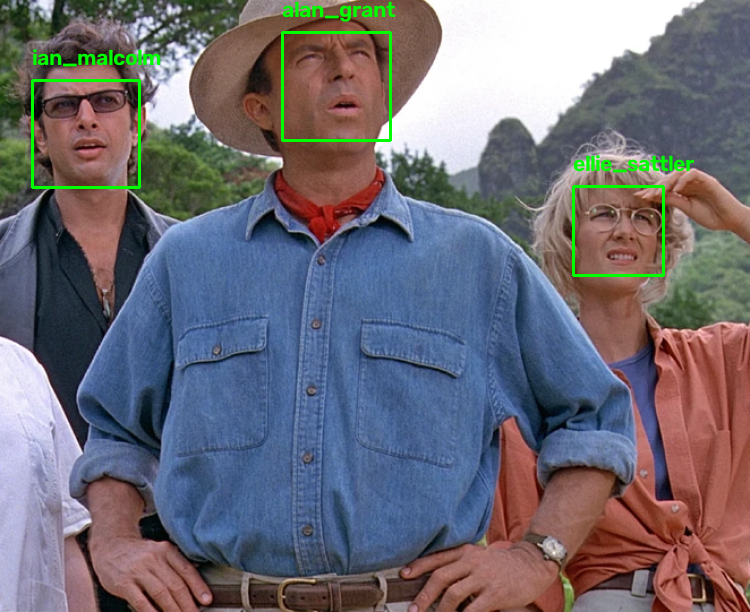

In [22]:

print("[INFO] Cargando encodings y reconociendo rostros...")

# Definir rutas
ruta_encodings = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/dataset/encodings.pickle"
# Ruta del imagen de prueba
ruta_imagen_prueba = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/examples/reparto.png"

# Cargar los datos conocidos (el "cerebro" del modelo)
data = pickle.loads(open(ruta_encodings, "rb").read())

# Cargar la imagen de prueba y prepararla
image = cv2.imread(ruta_imagen_prueba)
# Redimensionamos la imagen si es muy grande para que procese mas rapido
# imutils nos ayuda a mantener la proporción (aspect ratio)
image = imutils.resize(image, width=750)

# Convertir BGR a RGB
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Detectar rostros y extraer encodings de la imagen de prueba
print("[INFO] Detectando rostros en la imagen...")
boxes = face_recognition.face_locations(rgb, model="hog")
encodings = face_recognition.face_encodings(rgb, boxes)

# Lista para guardar los nombres detectados
names = []

# Bucle principal de reconocimiento
for encoding in encodings:
    # Comparamos el rostro detectado con todos los rostros conocido
    matches = face_recognition.compare_faces(data["encodings"], encoding, tolerance=0.5)
    name = "Desconocido" # Valor por defecto si no hay coincidencias

    # Si hay al menos un "True" en nuestras coincidencias
    if True in matches:
        # Encontramos los indices de todas las coincidencias (votos positivos)
        matchedIdxs = [i for (i, b) in enumerate(matches) if b]
        counts = {}

        # Contamos cuantos "votos" tiene cada personaje
        for i in matchedIdxs:
            nombre_conocido = data["names"][i]
            counts[nombre_conocido] = counts.get(nombre_conocido, 0) + 1

        # Determinamos el ganador (el nombre con mas votos)
        name = max(counts, key=counts.get)

    names.append(name)

# Dibujar los resultados en la imagen
for ((top, right, bottom, left), name) in zip(boxes, names):
    # Dibujar el rectangulo alrededor del rostro
    # Color verde (0, 255, 0) y grosor de 2 pixeles
    cv2.rectangle(image, (left, top), (right, bottom), (0, 255, 0), 2)

    # Dibujar el nombre arriba del rostro
    y = top - 15 if top - 15 > 15 else top + 15
    cv2.putText(image, name, (left, y), cv2.FONT_HERSHEY_SIMPLEX,
                0.75, (0, 255, 0), 2)

# 7. Mostrar la imagen final (Usando el parche de Google Colab)
print("[INFO] ¡Reconocimiento finalizado! Mostrando resultados:")
cv2_imshow(image)

**Reconocimiento Facial Gladys**

En este apartado utilizo el archivo procesado para el reconocimiento del personaje. Se utiliza un directorios de imagenes para realizar la prueba

[INFO] Cargando encodings y preparandose para reconocer multiples imagenes...
[INFO] Se encontraron 6 imágenes para analizar.

[INFO] Procesando imagen 1/6: gladys1.jpeg


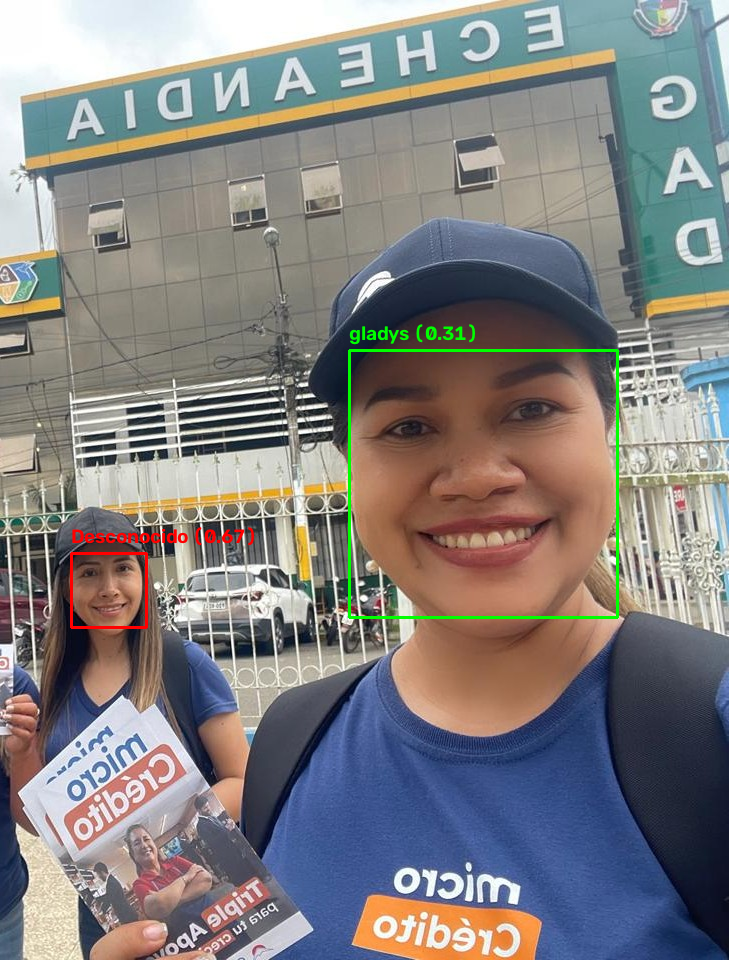


[INFO] Procesando imagen 2/6: gladys2.jpeg


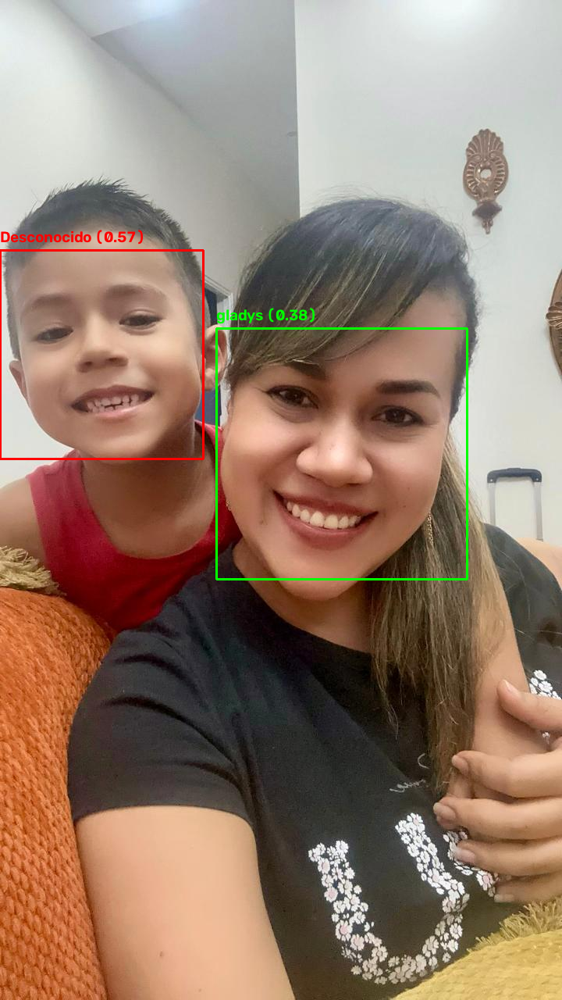


[INFO] Procesando imagen 3/6: gladys3.jpeg


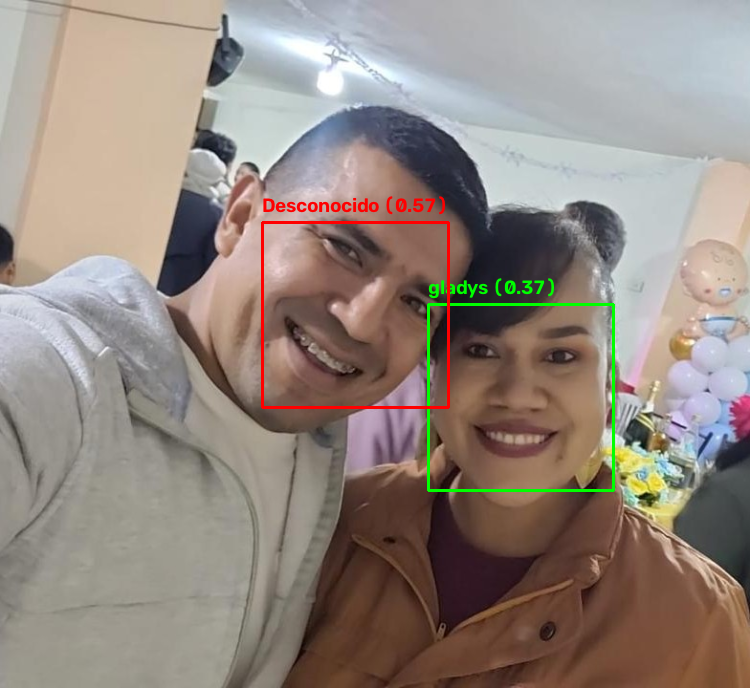


[INFO] Procesando imagen 4/6: gladys4.jpeg


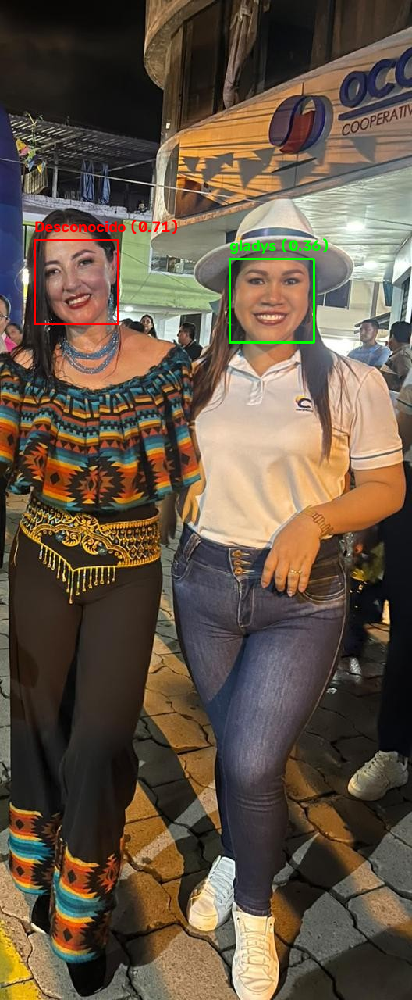


[INFO] Procesando imagen 5/6: gladys5.jpeg


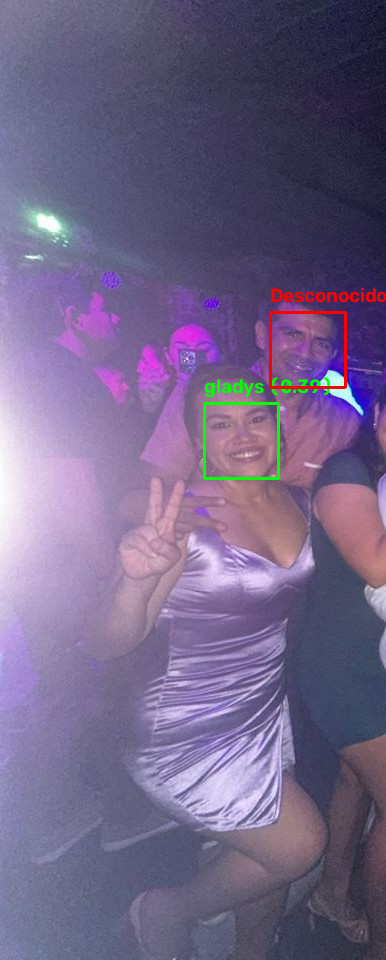


[INFO] Procesando imagen 6/6: gladys6.jpeg


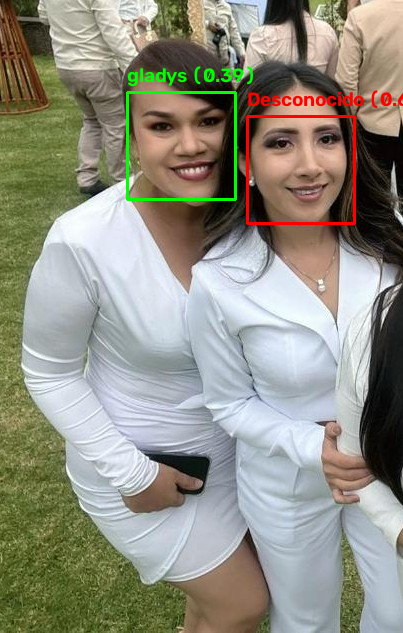

In [24]:


print("[INFO] Cargando encodings y preparandose para reconocer multiples imagenes...")

# Definir rutas y parametros
RUTA_ENCODINGS = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/dataset/encodings.pickle"
RUTA_CARPETA_PRUEBAS = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/examples/gladys_img/"
TOLERANCE = 0.5
MAX_WIDTH = 750

# Cargar datos conocidos de forma segura y vectorizar en NumPy
with open(RUTA_ENCODINGS, "rb") as f:
    data = pickle.load(f)

known_encodings = np.asarray(data["encodings"])
known_names = np.asarray(
    list(data["names"].values()) if isinstance(data["names"], dict) else data["names"]
)

image_paths = sorted(list(paths.list_images(RUTA_CARPETA_PRUEBAS)))
print(f"[INFO] Se encontraron {len(image_paths)} imágenes para analizar.")

# Iterar y procesar cada imagen
for idx, image_path in enumerate(image_paths, start=1):
    nombre_archivo = os.path.basename(image_path)
    print(f"\n[INFO] Procesando imagen {idx}/{len(image_paths)}: {nombre_archivo}")

    image = cv2.imread(image_path)
    if image is None:
        print(f"[ERROR] No se pudo cargar la imagen: {image_path}")
        continue

    # Redimensionar solo si excede el ancho maximo
    if image.shape[1] > MAX_WIDTH:
        image = imutils.resize(image, width=MAX_WIDTH)

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Detectar rostros y extraer encodings
    boxes = face_recognition.face_locations(rgb, model="hog")
    encodings = face_recognition.face_encodings(rgb, boxes)

    # Reconocimiento por menor distancia euclidiana y visualizacion
    for (top, right, bottom, left), encoding in zip(boxes, encodings):
        distances = face_recognition.face_distance(known_encodings, encoding)
        best_idx = np.argmin(distances)
        min_dist = distances[best_idx]

        if min_dist <= TOLERANCE:
            label = f"{known_names[best_idx]} ({min_dist:.2f})"
            color = (0, 255, 0)  # Verde para reconocido
        else:
            label = f"Desconocido ({min_dist:.2f})"
            color = (0, 0, 255)  # Rojo para desconocido

        # Dibujar cuadro delimitador y etiqueta con fondo legible
        cv2.rectangle(image, (left, top), (right, bottom), color, 2)
        y_text = top - 10 if top - 10 > 15 else bottom + 20
        cv2.putText(image, label, (left, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.65, color, 2)

    # Mostrar resultado y liberar memoria
    cv2_imshow(image)
    del image, rgb
    gc.collect()

Como podemos apeciar tenemos una respuesta favorable reconociendo al personaje sin ningun problema.

**Reconocimiento Facial Edison**

En este apartado realizamo lo mismo que en el apartado anterior esperando tener las mismas resuestas favorables.

[INFO] Cargando encodings y preparandose para reconocer multiples imagenes...
[INFO] Se encontraron 6 imágenes para analizar.

[INFO] Procesando imagen 1/6: eddy.jpeg


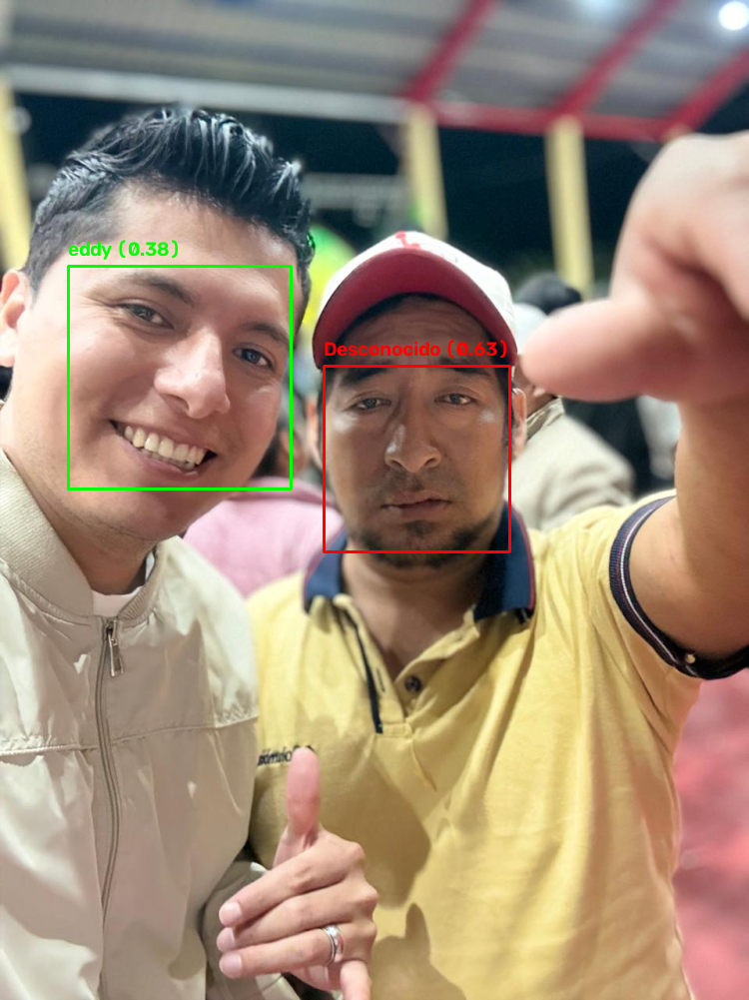


[INFO] Procesando imagen 2/6: eddy1.jpeg


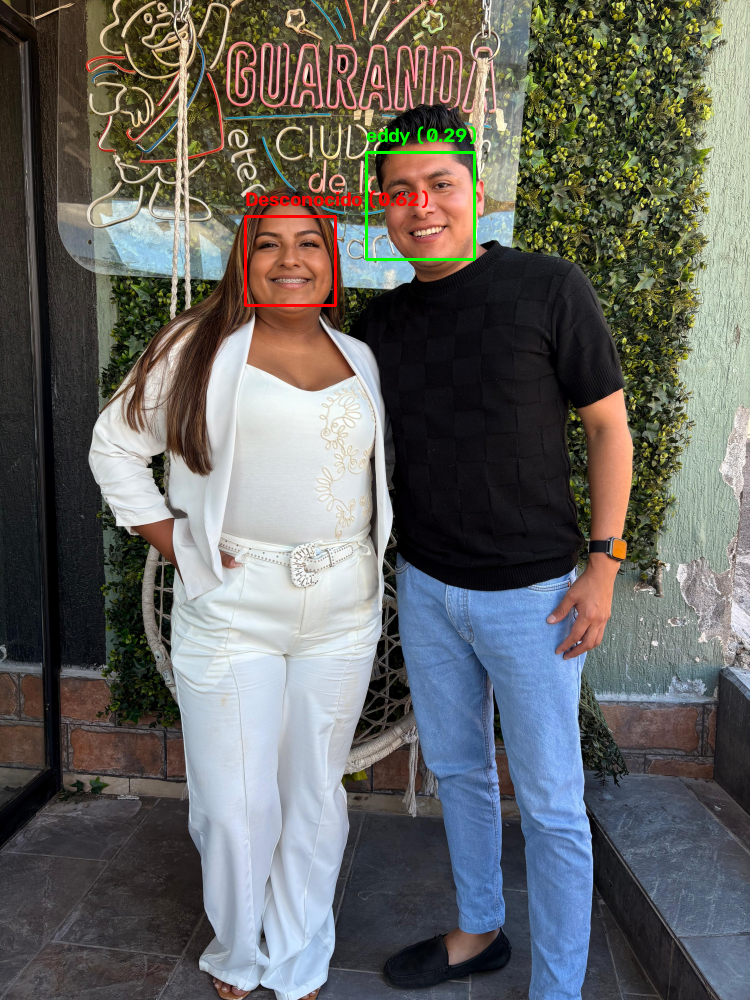


[INFO] Procesando imagen 3/6: eddy2.jpeg


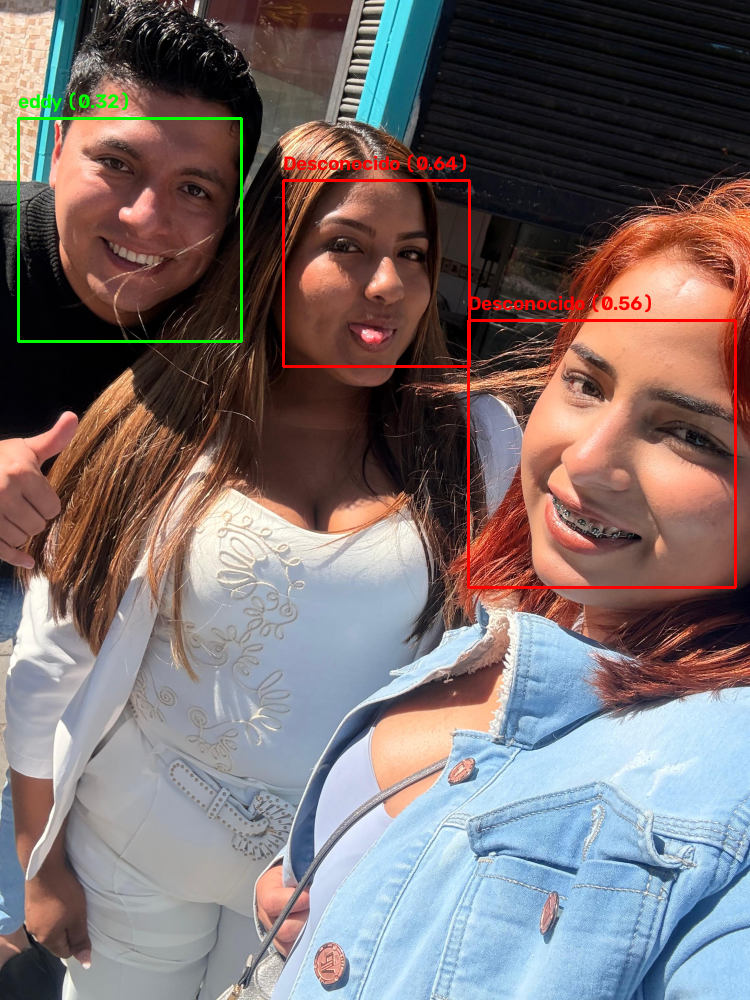


[INFO] Procesando imagen 4/6: eddy3.jpeg


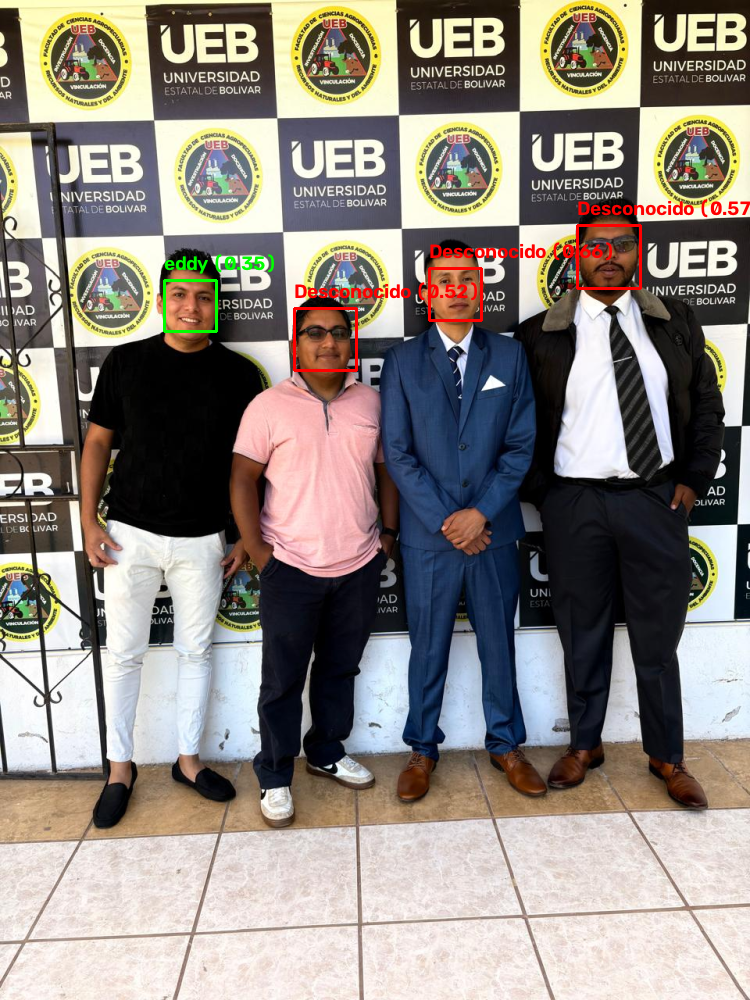


[INFO] Procesando imagen 5/6: eddy_ejemplo1.JPG


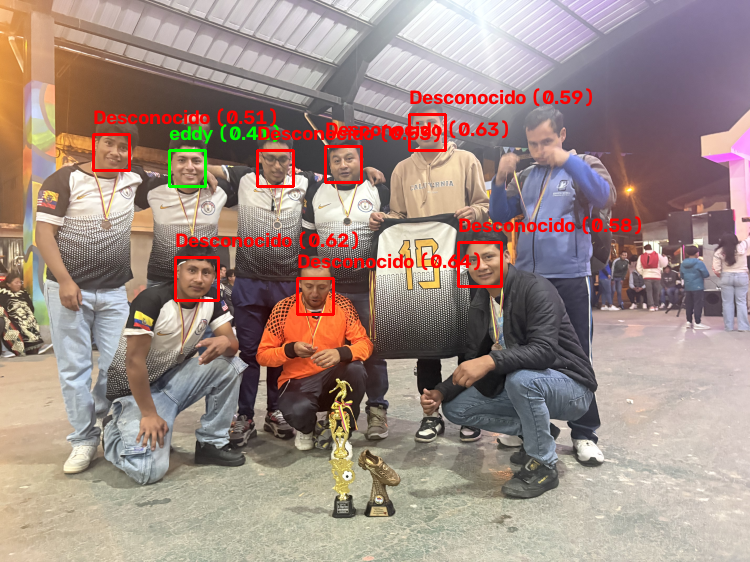


[INFO] Procesando imagen 6/6: eddy_ejemplo2.jpg


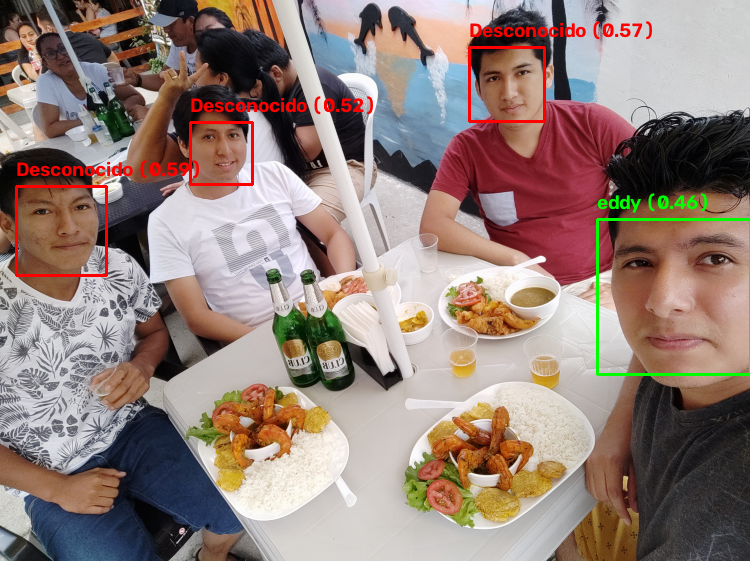

In [27]:


print("[INFO] Cargando encodings y preparandose para reconocer multiples imagenes...")

# Definir rutas y parametros
RUTA_ENCODINGS = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/dataset/encodings.pickle"
RUTA_CARPETA_PRUEBAS = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/examples/eddy_img/"
TOLERANCE = 0.5
MAX_WIDTH = 750

# Cargar datos conocidos de forma segura y vectorizar en NumPy
with open(RUTA_ENCODINGS, "rb") as f:
    data = pickle.load(f)

known_encodings = np.asarray(data["encodings"])
known_names = np.asarray(
    list(data["names"].values()) if isinstance(data["names"], dict) else data["names"]
)

image_paths = sorted(list(paths.list_images(RUTA_CARPETA_PRUEBAS)))
print(f"[INFO] Se encontraron {len(image_paths)} imágenes para analizar.")

# Iterar y procesar cada imagen
for idx, image_path in enumerate(image_paths, start=1):
    nombre_archivo = os.path.basename(image_path)
    print(f"\n[INFO] Procesando imagen {idx}/{len(image_paths)}: {nombre_archivo}")

    image = cv2.imread(image_path)
    if image is None:
        print(f"[ERROR] No se pudo cargar la imagen: {image_path}")
        continue

    # Redimensionar solo si excede el ancho maximo
    if image.shape[1] > MAX_WIDTH:
        image = imutils.resize(image, width=MAX_WIDTH)

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Detectar rostros y extraer encodings
    boxes = face_recognition.face_locations(rgb, model="hog")
    encodings = face_recognition.face_encodings(rgb, boxes)

    # Reconocimiento por menor distancia euclidiana y visualización
    for (top, right, bottom, left), encoding in zip(boxes, encodings):
        distances = face_recognition.face_distance(known_encodings, encoding)
        best_idx = np.argmin(distances)
        min_dist = distances[best_idx]

        if min_dist <= TOLERANCE:
            label = f"{known_names[best_idx]} ({min_dist:.2f})"
            color = (0, 255, 0)  # Verde para reconocido
        else:
            label = f"Desconocido ({min_dist:.2f})"
            color = (0, 0, 255)  # Rojo para desconocido

        # Dibujar cuadro delimitador y etiqueta con fondo legible
        cv2.rectangle(image, (left, top), (right, bottom), color, 2)
        y_text = top - 10 if top - 10 > 15 else bottom + 20
        cv2.putText(image, label, (left, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.65, color, 2)

    # Mostrar resultado y liberar memoria
    cv2_imshow(image)
    del image, rgb
    gc.collect()

Como podemos notar el usuario edison se puede direncias de los demas, dando como un resultado favorable

# Video


**Configuración del entorno e importaciones**

En este apartado realizamos todas las configuraciones y paramatros para el modelo de reconocimento facial en video

In [29]:
# Rutas del proyecto
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/"
RUTA_ENCODINGS = os.path.join(BASE_DIR, "dataset/encodings.pickle")
RUTA_VIDEO_ENTRADA = os.path.join(BASE_DIR, "videos/lunch_scene_corto.mp4")
RUTA_VIDEO_TEMP = "/content/salida_temp.mp4"
RUTA_VIDEO_FINAL = os.path.join(BASE_DIR, "output/lunch_scene_output.mp4")

# Parametros globales de inferencia
CONFIG = {
    "tolerance": 0.5,     # Umbral de distancia euclidiana
    "max_width": 640,      # Ancho maximo para acelerar detección
    "frame_skip": 3,       # Procesar 1 de cada N fotogramas
    "model": "hog"         # "hog" para CPU
}

print("[OK] Entorno y configuracion inicializados.")

[OK] Entorno y configuracion inicializados.


**Módulo de carga de Encodings**

Lee el archivo encodings.pickle y lo transforma en arreglos vectorizados de NumPy para que la comparación de distancias sea instantánea.

In [31]:
# Cargo el encodings para el reconociento
def cargar_encodings(ruta_pickle):
    if not os.path.exists(ruta_pickle):
        raise FileNotFoundError(f"No se encontro el archivo de encodings en: {ruta_pickle}")

    with open(ruta_pickle, "rb") as f:
        data = pickle.load(f)

    known_encodings = np.asarray(data["encodings"])
    known_names = np.asarray(
        list(data["names"].values()) if isinstance(data["names"], dict) else data["names"]
    )
    print(f"[OK] Cargados {len(known_encodings)} embeddings de {len(np.unique(known_names))} personajes.")
    return known_encodings, known_names

known_encodings, known_names = cargar_encodings(RUTA_ENCODINGS)

[OK] Cargados 232 embeddings de 8 personajes.


**Modulo de deteccion y anotacion de fotogramas**

Separa la logica de vision artificial (detectar rostros, calcular distancias y dibujar etiquetas) del manejo de archivos de video.

In [33]:
def detectar_rostros_frame(frame_bgr, known_encodings, known_names, tolerance=0.5, model="hog"):
    """Detecta e identifica rostros en un fotograma individual."""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    boxes = face_recognition.face_locations(rgb, model=model)
    encodings = face_recognition.face_encodings(rgb, boxes)

    detecciones = []
    for (top, right, bottom, left), encoding in zip(boxes, encodings):
        distances = face_recognition.face_distance(known_encodings, encoding)
        best_idx = np.argmin(distances)
        min_dist = distances[best_idx]

        if min_dist <= tolerance:
            label = f"{known_names[best_idx]} ({min_dist:.2f})"
            color = (0, 220, 0)  # Verde
        else:
            label = f"Desconocido ({min_dist:.2f})"
            color = (0, 0, 255)  # Rojo

        detecciones.append(((top, right, bottom, left), label, color))

    return detecciones

def dibujar_detecciones(frame_bgr, detecciones):
    """Dibuja los cuadros delimitadores y etiquetas con fondo solido sobre el fotograma."""
    for (top, right, bottom, left), label, color in detecciones:
        cv2.rectangle(frame_bgr, (left, top), (right, bottom), color, 2)

        y_text = top - 10 if top - 10 > 15 else bottom + 20
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
        cv2.rectangle(frame_bgr, (left, y_text - th - 4), (left + tw + 4, y_text + 4), color, -1)
        cv2.putText(frame_bgr, label, (left + 2, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

    return frame_bgr

print("[OK] Funciones de deteccion y dibujo listas.")

[OK] Funciones de deteccion y dibujo listas.


**Modulo de procesamiento de flujo de video**

Coordina la lectura del video original, aplica el salto de fotogramas (frame_skip) usando las funciones del Paso 3 y exporta el video

In [34]:
def procesar_flujo_video(video_in, video_temp, known_encodings, known_names, config):
    if not os.path.exists(video_in):
        raise FileNotFoundError(f"No se encontro el video de entrada: {video_in}")

    cap = cv2.VideoCapture(video_in)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Calcular dimensiones escaladas
    max_w = config["max_width"]
    if orig_w > max_w:
        out_w = max_w
        out_h = int(orig_h * (max_w / float(orig_w)))
    else:
        out_w, out_h = orig_w, orig_h

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(video_temp, fourcc, fps, (out_w, out_h))

    print(f"[INFO] Procesando {out_w}x{out_h} @ {fps:.1f} FPS (~{total_frames} frames)...")
    inicio = time.time()
    frame_count = 0
    ultimas_detecciones = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame.shape[1] != out_w:
            frame = cv2.resize(frame, (out_w, out_h), interpolation=cv2.INTER_AREA)

        # Inferencia cada N fotogramas
        if frame_count % config["frame_skip"] == 0:
            ultimas_detecciones = detectar_rostros_frame(
                frame,
                known_encodings,
                known_names,
                tolerance=config["tolerance"],
                model=config["model"]
            )

        frame = dibujar_detecciones(frame, ultimas_detecciones)
        writer.write(frame)
        frame_count += 1

        if frame_count % 100 == 0:
            print(f"   -> {frame_count}/{total_frames if total_frames > 0 else '?'} frames procesados...")
            gc.collect()

    cap.release()
    writer.release()

    duracion = time.time() - inicio
    print(f"[OK] Procesamiento finalizado en {duracion:.2f}s ({frame_count / max(duracion, 0.1):.1f} FPS).")

procesar_flujo_video(RUTA_VIDEO_ENTRADA, RUTA_VIDEO_TEMP, known_encodings, known_names, CONFIG)

[INFO] Procesando 640x351 @ 30.0 FPS (~1853 frames)...
   -> 100/1853 frames procesados...
   -> 200/1853 frames procesados...
   -> 300/1853 frames procesados...
   -> 400/1853 frames procesados...
   -> 500/1853 frames procesados...
   -> 600/1853 frames procesados...
   -> 700/1853 frames procesados...
   -> 800/1853 frames procesados...
   -> 900/1853 frames procesados...
   -> 1000/1853 frames procesados...
   -> 1100/1853 frames procesados...
   -> 1200/1853 frames procesados...
   -> 1300/1853 frames procesados...
   -> 1400/1853 frames procesados...
   -> 1500/1853 frames procesados...
   -> 1600/1853 frames procesados...
   -> 1700/1853 frames procesados...
   -> 1800/1853 frames procesados...
[OK] Procesamiento finalizado en 198.11s (9.4 FPS).


**Modulo de codificación H.264 y visualizacion en Colab**

Convierte el archivo temporal al codec estandar H.264 (para que pueda reproducirse en navegadores y Google Drive) y lo muestra directamente en el notebook.

In [35]:
def exportar_y_mostrar_video(video_temp, video_final, ancho_visor=640):
    if not os.path.exists(video_temp):
        print("[ERROR] No se encontro el video temporal para convertir.")
        return

    os.makedirs(os.path.dirname(video_final), exist_ok=True)
    print("[INFO] Convirtiendo video a H.264...")

    subprocess.run(
        ["ffmpeg", "-y", "-i", video_temp, "-vcodec", "libx264", "-crf", "23", "-preset", "fast", video_final],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )
    os.remove(video_temp)
    print(f"[OK] Video guardado en: {video_final}")

    # Mostrar reproductor si el archivo pesa menos de 25 MB
    tamano_mb = os.path.getsize(video_final) / (1024 * 1024)
    if tamano_mb <= 25:
        with open(video_final, "rb") as f:
            data_url = "data:video/mp4;base64," + b64encode(f.read()).decode()
        display(HTML(f'<video width={ancho_visor} controls><source src="{data_url}" type="video/mp4"></video>'))
    else:
        print(f"[INFO] El video pesa {tamano_mb:.1f} MB (supera el limite recomendado para vista previa embebida). Descargalo directamente desde Drive.")

exportar_y_mostrar_video(RUTA_VIDEO_TEMP, RUTA_VIDEO_FINAL)

[INFO] Convirtiendo video a H.264...
[OK] Video guardado en: /content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/output/lunch_scene_output.mp4


**Reconocimiento por video edison**

Ahora en este apartado realizamos lo mismo para el video del actor Edison

In [36]:
# Rutas del proyecto
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/"
RUTA_ENCODINGS = os.path.join(BASE_DIR, "dataset/encodings.pickle")
RUTA_VIDEO_ENTRADA = os.path.join(BASE_DIR, "videos/eddy_video.mp4")
RUTA_VIDEO_TEMP = "/content/salida_temp.mp4"
RUTA_VIDEO_FINAL = os.path.join(BASE_DIR, "output/eddy_video_output.mp4")

# Parametros globales de inferencia
CONFIG = {
    "tolerance": 0.5,     # Umbral de distancia euclidiana
    "max_width": 640,      # Ancho maximo para acelerar deteccion
    "frame_skip": 3,       # Procesar 1 de cada N fotogramas
    "model": "hog"         # "hog" para CPU
}

print("[OK] Entorno y configuracion inicializados.")

[OK] Entorno y configuracion inicializados.


In [37]:
def cargar_encodings(ruta_pickle):
    if not os.path.exists(ruta_pickle):
        raise FileNotFoundError(f"No se encontra el archivo de encodings en: {ruta_pickle}")

    with open(ruta_pickle, "rb") as f:
        data = pickle.load(f)

    known_encodings = np.asarray(data["encodings"])
    known_names = np.asarray(
        list(data["names"].values()) if isinstance(data["names"], dict) else data["names"]
    )
    print(f"[OK] Cargados {len(known_encodings)} embeddings de {len(np.unique(known_names))} personajes.")
    return known_encodings, known_names

known_encodings, known_names = cargar_encodings(RUTA_ENCODINGS)

[OK] Cargados 232 embeddings de 8 personajes.


In [39]:
def detectar_rostros_frame(frame_bgr, known_encodings, known_names, tolerance=0.5, model="hog"):
    """Detecta e identifica rostros en un fotograma individual."""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    boxes = face_recognition.face_locations(rgb, model=model)
    encodings = face_recognition.face_encodings(rgb, boxes)

    detecciones = []
    for (top, right, bottom, left), encoding in zip(boxes, encodings):
        distances = face_recognition.face_distance(known_encodings, encoding)
        best_idx = np.argmin(distances)
        min_dist = distances[best_idx]

        if min_dist <= tolerance:
            label = f"{known_names[best_idx]} ({min_dist:.2f})"
            color = (0, 220, 0)  # Verde
        else:
            label = f"Desconocido ({min_dist:.2f})"
            color = (0, 0, 255)  # Rojo

        detecciones.append(((top, right, bottom, left), label, color))

    return detecciones

def dibujar_detecciones(frame_bgr, detecciones):
    """Dibuja los cuadros delimitadores y etiquetas con fondo solido sobre el fotograma."""
    for (top, right, bottom, left), label, color in detecciones:
        cv2.rectangle(frame_bgr, (left, top), (right, bottom), color, 2)

        y_text = top - 10 if top - 10 > 15 else bottom + 20
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
        cv2.rectangle(frame_bgr, (left, y_text - th - 4), (left + tw + 4, y_text + 4), color, -1)
        cv2.putText(frame_bgr, label, (left + 2, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

    return frame_bgr

print("[OK] Funciones de deteccion y dibujo listas.")

[OK] Funciones de deteccion y dibujo listas.


In [46]:
def procesar_flujo_video(video_in, video_temp, known_encodings, known_names, config):
    if not os.path.exists(video_in):
        raise FileNotFoundError(f"No se encontro el video de entrada: {video_in}")

    cap = cv2.VideoCapture(video_in)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Calcular dimensiones escaladas
    max_w = config["max_width"]
    if orig_w > max_w:
        out_w = max_w
        out_h = int(orig_h * (max_w / float(orig_w)))
    else:
        out_w, out_h = orig_w, orig_h

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(video_temp, fourcc, fps, (out_w, out_h))

    print(f"[INFO] Procesando {out_w}x{out_h} @ {fps:.1f} FPS (~{total_frames} frames)...")
    inicio = time.time()
    frame_count = 0
    ultimas_detecciones = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame.shape[1] != out_w:
            frame = cv2.resize(frame, (out_w, out_h), interpolation=cv2.INTER_AREA)

        # Inferencia cada N fotogramas
        if frame_count % config["frame_skip"] == 0:
            ultimas_detecciones = detectar_rostros_frame(
                frame,
                known_encodings,
                known_names,
                tolerance=config["tolerance"],
                model=config["model"]
            )

        frame = dibujar_detecciones(frame, ultimas_detecciones)
        writer.write(frame)
        frame_count += 1

        if frame_count % 100 == 0:
            print(f"   -> {frame_count}/{total_frames if total_frames > 0 else '?'} frames procesados...")
            gc.collect()

    cap.release()
    writer.release()

    duracion = time.time() - inicio
    print(f"[OK] Procesamiento finalizado en {duracion:.2f}s ({frame_count / max(duracion, 0.1):.1f} FPS).")

procesar_flujo_video(RUTA_VIDEO_ENTRADA, RUTA_VIDEO_TEMP, known_encodings, known_names, CONFIG)

[INFO] Procesando 640x1137 @ 25.2 FPS (~249 frames)...
   -> 100/249 frames procesados...
   -> 200/249 frames procesados...
[OK] Procesamiento finalizado en 68.15s (3.7 FPS).


In [47]:
def exportar_y_mostrar_video(video_temp, video_final, ancho_visor=640):
    if not os.path.exists(video_temp):
        print("[ERROR] No se encontro el video temporal para convertir.")
        return

    os.makedirs(os.path.dirname(video_final), exist_ok=True)
    print("[INFO] Convirtiendo video a H.264...")

    subprocess.run(
        ["ffmpeg", "-y", "-i", video_temp, "-vcodec", "libx264", "-crf", "23", "-preset", "fast", video_final],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )
    os.remove(video_temp)
    print(f"[OK] Video guardado en: {video_final}")

    # Mostrar reproductor si el archivo pesa menos de 25 MB
    tamano_mb = os.path.getsize(video_final) / (1024 * 1024)
    if tamano_mb <= 25:
        with open(video_final, "rb") as f:
            data_url = "data:video/mp4;base64," + b64encode(f.read()).decode()
        display(HTML(f'<video width={ancho_visor} controls><source src="{data_url}" type="video/mp4"></video>'))
    else:
        print(f"[INFO] El video pesa {tamano_mb:.1f} MB (supera el limite recomendado para vista previa embebida)")

exportar_y_mostrar_video(RUTA_VIDEO_TEMP, RUTA_VIDEO_FINAL)

[INFO] Convirtiendo video a H.264...
[OK] Video guardado en: /content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/output/eddy_video_output.mp4


Como podemos ver en base de que no hay suficiente iluminacion el modelo reconoce correctamente el personaje

**Reconocimiento de video gladys**

In [48]:
# Rutas del proyecto
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/"
RUTA_ENCODINGS = os.path.join(BASE_DIR, "dataset/encodings.pickle")
RUTA_VIDEO_ENTRADA = os.path.join(BASE_DIR, "videos/gladys_video.mp4")
RUTA_VIDEO_TEMP = "/content/salida_temp.mp4"
RUTA_VIDEO_FINAL = os.path.join(BASE_DIR, "output/gladys_video_output.mp4")

# Parametros globales de inferencia
CONFIG = {
    "tolerance": 0.5,     # Umbral de distancia euclidiana
    "max_width": 640,      # Ancho maximo para acelerar deteccion
    "frame_skip": 3,       # Procesar 1 de cada N fotogramas
    "model": "hog"         # "hog" para CPU
}

print("[OK] Entorno y configuracion inicializados.")

[OK] Entorno y configuracion inicializados.


In [49]:
def cargar_encodings(ruta_pickle):
    if not os.path.exists(ruta_pickle):
        raise FileNotFoundError(f"No se encontro el archivo de encodings en: {ruta_pickle}")

    with open(ruta_pickle, "rb") as f:
        data = pickle.load(f)

    known_encodings = np.asarray(data["encodings"])
    known_names = np.asarray(
        list(data["names"].values()) if isinstance(data["names"], dict) else data["names"]
    )
    print(f"[OK] Cargados {len(known_encodings)} embeddings de {len(np.unique(known_names))} personajes.")
    return known_encodings, known_names

known_encodings, known_names = cargar_encodings(RUTA_ENCODINGS)

[OK] Cargados 232 embeddings de 8 personajes.


In [50]:
def detectar_rostros_frame(frame_bgr, known_encodings, known_names, tolerance=0.52, model="hog"):
    """Detecta e identifica rostros en un fotograma individual."""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    boxes = face_recognition.face_locations(rgb, model=model)
    encodings = face_recognition.face_encodings(rgb, boxes)

    detecciones = []
    for (top, right, bottom, left), encoding in zip(boxes, encodings):
        distances = face_recognition.face_distance(known_encodings, encoding)
        best_idx = np.argmin(distances)
        min_dist = distances[best_idx]

        if min_dist <= tolerance:
            label = f"{known_names[best_idx]} ({min_dist:.2f})"
            color = (0, 220, 0)  # Verde
        else:
            label = f"Desconocido ({min_dist:.2f})"
            color = (0, 0, 255)  # Rojo

        detecciones.append(((top, right, bottom, left), label, color))

    return detecciones

def dibujar_detecciones(frame_bgr, detecciones):
    """Dibuja los cuadros delimitadores y etiquetas con fondo solido sobre el fotograma."""
    for (top, right, bottom, left), label, color in detecciones:
        cv2.rectangle(frame_bgr, (left, top), (right, bottom), color, 2)

        y_text = top - 10 if top - 10 > 15 else bottom + 20
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
        cv2.rectangle(frame_bgr, (left, y_text - th - 4), (left + tw + 4, y_text + 4), color, -1)
        cv2.putText(frame_bgr, label, (left + 2, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

    return frame_bgr

print("[OK] Funciones de deteccion y dibujo listas.")

[OK] Funciones de deteccion y dibujo listas.


In [51]:
def procesar_flujo_video(video_in, video_temp, known_encodings, known_names, config):
    if not os.path.exists(video_in):
        raise FileNotFoundError(f"No se encontro el video de entrada: {video_in}")

    cap = cv2.VideoCapture(video_in)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Calcular dimensiones escaladas
    max_w = config["max_width"]
    if orig_w > max_w:
        out_w = max_w
        out_h = int(orig_h * (max_w / float(orig_w)))
    else:
        out_w, out_h = orig_w, orig_h

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(video_temp, fourcc, fps, (out_w, out_h))

    print(f"[INFO] Procesando {out_w}x{out_h} @ {fps:.1f} FPS (~{total_frames} frames)...")
    inicio = time.time()
    frame_count = 0
    ultimas_detecciones = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame.shape[1] != out_w:
            frame = cv2.resize(frame, (out_w, out_h), interpolation=cv2.INTER_AREA)

        # Inferencia cada N fotogramas
        if frame_count % config["frame_skip"] == 0:
            ultimas_detecciones = detectar_rostros_frame(
                frame,
                known_encodings,
                known_names,
                tolerance=config["tolerance"],
                model=config["model"]
            )

        frame = dibujar_detecciones(frame, ultimas_detecciones)
        writer.write(frame)
        frame_count += 1

        if frame_count % 100 == 0:
            print(f"   -> {frame_count}/{total_frames if total_frames > 0 else '?'} frames procesados...")
            gc.collect()

    cap.release()
    writer.release()

    duracion = time.time() - inicio
    print(f"[OK] Procesamiento finalizado en {duracion:.2f}s ({frame_count / max(duracion, 0.1):.1f} FPS).")

procesar_flujo_video(RUTA_VIDEO_ENTRADA, RUTA_VIDEO_TEMP, known_encodings, known_names, CONFIG)

[INFO] Procesando 576x1024 @ 17.0 FPS (~189 frames)...
   -> 100/189 frames procesados...
[OK] Procesamiento finalizado en 44.76s (4.2 FPS).


In [52]:
def exportar_y_mostrar_video(video_temp, video_final, ancho_visor=640):
    if not os.path.exists(video_temp):
        print("[ERROR] No se encontro el video temporal para convertir.")
        return

    os.makedirs(os.path.dirname(video_final), exist_ok=True)
    print("[INFO] Convirtiendo video a H.264...")

    subprocess.run(
        ["ffmpeg", "-y", "-i", video_temp, "-vcodec", "libx264", "-crf", "23", "-preset", "fast", video_final],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )
    os.remove(video_temp)
    print(f"[OK] Video guardado en: {video_final}")

    # Mostrar reproductor si el archivo pesa menos de 25 MB
    tamano_mb = os.path.getsize(video_final) / (1024 * 1024)
    if tamano_mb <= 25:
        with open(video_final, "rb") as f:
            data_url = "data:video/mp4;base64," + b64encode(f.read()).decode()
        display(HTML(f'<video width={ancho_visor} controls><source src="{data_url}" type="video/mp4"></video>'))
    else:
        print(f"[INFO] El video pesa {tamano_mb:.1f} MB (supera el limite recomendado para vista previa embebida).")

exportar_y_mostrar_video(RUTA_VIDEO_TEMP, RUTA_VIDEO_FINAL)

[INFO] Convirtiendo video a H.264...
[OK] Video guardado en: /content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/output/gladys_video_output.mp4


Como se puede observar el modelo indentifica correctamente el personaje

# Video 2 personajes Edison y Gladys

In [53]:
# Rutas del proyecto
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/"
RUTA_ENCODINGS = os.path.join(BASE_DIR, "dataset/encodings.pickle")
RUTA_VIDEO_ENTRADA = os.path.join(BASE_DIR, "videos/video_eddy_gladys2.mp4")
RUTA_VIDEO_TEMP = "/content/salida_temp.mp4"
RUTA_VIDEO_FINAL = os.path.join(BASE_DIR, "output/eddy_gladys2_video_output.mp4")

# Parametros globales de inferencia
CONFIG = {
    "tolerance": 0.5,     # Umbral de distancia euclidiana
    "max_width": 640,      # Ancho maximo para acelerar detección
    "frame_skip": 3,       # Procesar 1 de cada N fotogramas
    "model": "hog"         # "hog" para CPU
}

print("[OK] Entorno y configuracion inicializados.")

[OK] Entorno y configuracion inicializados.


In [54]:
def cargar_encodings(ruta_pickle):
    if not os.path.exists(ruta_pickle):
        raise FileNotFoundError(f"No se encontro el archivo de encodings en: {ruta_pickle}")

    with open(ruta_pickle, "rb") as f:
        data = pickle.load(f)

    known_encodings = np.asarray(data["encodings"])
    known_names = np.asarray(
        list(data["names"].values()) if isinstance(data["names"], dict) else data["names"]
    )
    print(f"[OK] Cargados {len(known_encodings)} embeddings de {len(np.unique(known_names))} personajes.")
    return known_encodings, known_names

known_encodings, known_names = cargar_encodings(RUTA_ENCODINGS)

[OK] Cargados 232 embeddings de 8 personajes.


In [55]:
def detectar_rostros_frame(frame_bgr, known_encodings, known_names, tolerance=0.52, model="hog"):
    """Detecta e identifica rostros en un fotograma individual."""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    boxes = face_recognition.face_locations(rgb, model=model)
    encodings = face_recognition.face_encodings(rgb, boxes)

    detecciones = []
    for (top, right, bottom, left), encoding in zip(boxes, encodings):
        distances = face_recognition.face_distance(known_encodings, encoding)
        best_idx = np.argmin(distances)
        min_dist = distances[best_idx]

        if min_dist <= tolerance:
            label = f"{known_names[best_idx]} ({min_dist:.2f})"
            color = (0, 220, 0)  # Verde
        else:
            label = f"Desconocido ({min_dist:.2f})"
            color = (0, 0, 255)  # Rojo

        detecciones.append(((top, right, bottom, left), label, color))

    return detecciones

def dibujar_detecciones(frame_bgr, detecciones):
    """Dibuja los cuadros delimitadores y etiquetas con fondo solido sobre el fotograma."""
    for (top, right, bottom, left), label, color in detecciones:
        cv2.rectangle(frame_bgr, (left, top), (right, bottom), color, 2)

        y_text = top - 10 if top - 10 > 15 else bottom + 20
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
        cv2.rectangle(frame_bgr, (left, y_text - th - 4), (left + tw + 4, y_text + 4), color, -1)
        cv2.putText(frame_bgr, label, (left + 2, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

    return frame_bgr

print("[OK] Funciones de deteccion y dibujo listas.")

[OK] Funciones de deteccion y dibujo listas.


In [56]:
def procesar_flujo_video(video_in, video_temp, known_encodings, known_names, config):
    if not os.path.exists(video_in):
        raise FileNotFoundError(f"No se encontro el video de entrada: {video_in}")

    cap = cv2.VideoCapture(video_in)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Calcular dimensiones escaladas
    max_w = config["max_width"]
    if orig_w > max_w:
        out_w = max_w
        out_h = int(orig_h * (max_w / float(orig_w)))
    else:
        out_w, out_h = orig_w, orig_h

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(video_temp, fourcc, fps, (out_w, out_h))

    print(f"[INFO] Procesando {out_w}x{out_h} @ {fps:.1f} FPS (~{total_frames} frames)...")
    inicio = time.time()
    frame_count = 0
    ultimas_detecciones = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame.shape[1] != out_w:
            frame = cv2.resize(frame, (out_w, out_h), interpolation=cv2.INTER_AREA)

        # Inferencia cada N fotogramas
        if frame_count % config["frame_skip"] == 0:
            ultimas_detecciones = detectar_rostros_frame(
                frame,
                known_encodings,
                known_names,
                tolerance=config["tolerance"],
                model=config["model"]
            )

        frame = dibujar_detecciones(frame, ultimas_detecciones)
        writer.write(frame)
        frame_count += 1

        if frame_count % 100 == 0:
            print(f"   -> {frame_count}/{total_frames if total_frames > 0 else '?'} frames procesados...")
            gc.collect()

    cap.release()
    writer.release()

    duracion = time.time() - inicio
    print(f"[OK] Procesamiento finalizado en {duracion:.2f}s ({frame_count / max(duracion, 0.1):.1f} FPS).")

procesar_flujo_video(RUTA_VIDEO_ENTRADA, RUTA_VIDEO_TEMP, known_encodings, known_names, CONFIG)

[INFO] Procesando 640x360 @ 30.0 FPS (~1062 frames)...
   -> 100/1062 frames procesados...
   -> 200/1062 frames procesados...
   -> 300/1062 frames procesados...
   -> 400/1062 frames procesados...
   -> 500/1062 frames procesados...
   -> 600/1062 frames procesados...
   -> 700/1062 frames procesados...
   -> 800/1062 frames procesados...
   -> 900/1062 frames procesados...
   -> 1000/1062 frames procesados...
[OK] Procesamiento finalizado en 144.90s (7.3 FPS).


In [57]:
def exportar_y_mostrar_video(video_temp, video_final, ancho_visor=640):
    if not os.path.exists(video_temp):
        print("[ERROR] No se encontro el video temporal para convertir.")
        return

    os.makedirs(os.path.dirname(video_final), exist_ok=True)
    print("[INFO] Convirtiendo video a H.264...")

    subprocess.run(
        ["ffmpeg", "-y", "-i", video_temp, "-vcodec", "libx264", "-crf", "23", "-preset", "fast", video_final],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )
    os.remove(video_temp)
    print(f"[OK] Video guardado en: {video_final}")

    # Mostrar reproductor si el archivo pesa menos de 25 MB
    tamano_mb = os.path.getsize(video_final) / (1024 * 1024)
    if tamano_mb <= 25:
        with open(video_final, "rb") as f:
            data_url = "data:video/mp4;base64," + b64encode(f.read()).decode()
        display(HTML(f'<video width={ancho_visor} controls><source src="{data_url}" type="video/mp4"></video>'))
    else:
        print(f"[INFO] El video pesa {tamano_mb:.1f} MB (supera el límite recomendado para vista previa embebida).")

exportar_y_mostrar_video(RUTA_VIDEO_TEMP, RUTA_VIDEO_FINAL)

[INFO] Convirtiendo video a H.264...
[OK] Video guardado en: /content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/output/eddy_gladys2_video_output.mp4


Como resultado tenemos que detecta correctamente a los personajes, teniendo en cuenta que un personaje tiene lentes y despues se los quita.

**Video Edison y Gladys**

Se realiza esta segunda prueba, llevando al limite al modelo el cual debe indenticar a los personajes mediante movimiento y escases de luz

In [73]:
# Rutas del proyecto
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/"
RUTA_ENCODINGS = os.path.join(BASE_DIR, "dataset/encodings.pickle")
RUTA_VIDEO_ENTRADA = os.path.join(BASE_DIR, "videos/video_eddy_gladys1.mp4")
RUTA_VIDEO_TEMP = "/content/salida_temp.mp4"
RUTA_VIDEO_FINAL = os.path.join(BASE_DIR, "output/eddy_gladys1_video_output.mp4")

# Parametros globales de inferencia
CONFIG = {
    "tolerance": 0.5,     # Umbral de distancia euclidiana
    "max_width": 640,      # Ancho maximo para acelerar detección
    "frame_skip": 3,       # Procesar 1 de cada N fotogramas
    "model": "hog"         # "hog" para CPU
}

print("[OK] Entorno y configuracion inicializados.")

[OK] Entorno y configuracion inicializados.


In [74]:
def cargar_encodings(ruta_pickle):
    if not os.path.exists(ruta_pickle):
        raise FileNotFoundError(f"No se encontro el archivo de encodings en: {ruta_pickle}")

    with open(ruta_pickle, "rb") as f:
        data = pickle.load(f)

    known_encodings = np.asarray(data["encodings"])
    known_names = np.asarray(
        list(data["names"].values()) if isinstance(data["names"], dict) else data["names"]
    )
    print(f"[OK] Cargados {len(known_encodings)} embeddings de {len(np.unique(known_names))} personajes.")
    return known_encodings, known_names

known_encodings, known_names = cargar_encodings(RUTA_ENCODINGS)

[OK] Cargados 232 embeddings de 8 personajes.


In [81]:
def detectar_rostros_frame(frame_bgr, known_encodings, known_names, tolerance=0.5, model="hog"):
    """Detecta e identifica rostros en un fotograma individual."""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    boxes = face_recognition.face_locations(rgb, model=model)
    encodings = face_recognition.face_encodings(rgb, boxes)

    detecciones = []
    for (top, right, bottom, left), encoding in zip(boxes, encodings):
        distances = face_recognition.face_distance(known_encodings, encoding)
        best_idx = np.argmin(distances)
        min_dist = distances[best_idx]

        if min_dist <= tolerance:
            label = f"{known_names[best_idx]} ({min_dist:.2f})"
            color = (0, 220, 0)  # Verde
        else:
            label = f"Desconocido ({min_dist:.2f})"
            color = (0, 0, 255)  # Rojo

        detecciones.append(((top, right, bottom, left), label, color))

    return detecciones

def dibujar_detecciones(frame_bgr, detecciones):
    """Dibuja los cuadros delimitadores y etiquetas con fondo solido sobre el fotograma."""
    for (top, right, bottom, left), label, color in detecciones:
        cv2.rectangle(frame_bgr, (left, top), (right, bottom), color, 2)

        y_text = top - 10 if top - 10 > 15 else bottom + 20
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
        cv2.rectangle(frame_bgr, (left, y_text - th - 4), (left + tw + 4, y_text + 4), color, -1)
        cv2.putText(frame_bgr, label, (left + 2, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

    return frame_bgr

print("[OK] Funciones de deteccion y dibujo listas.")

[OK] Funciones de deteccion y dibujo listas.


In [82]:
def procesar_flujo_video(video_in, video_temp, known_encodings, known_names, config):
    if not os.path.exists(video_in):
        raise FileNotFoundError(f"No se encontro el video de entrada: {video_in}")

    cap = cv2.VideoCapture(video_in)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Calcular dimensiones escaladas
    max_w = config["max_width"]
    if orig_w > max_w:
        out_w = max_w
        out_h = int(orig_h * (max_w / float(orig_w)))
    else:
        out_w, out_h = orig_w, orig_h

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(video_temp, fourcc, fps, (out_w, out_h))

    print(f"[INFO] Procesando {out_w}x{out_h} @ {fps:.1f} FPS (~{total_frames} frames)...")
    inicio = time.time()
    frame_count = 0
    ultimas_detecciones = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame.shape[1] != out_w:
            frame = cv2.resize(frame, (out_w, out_h), interpolation=cv2.INTER_AREA)

        # Inferencia cada N fotogramas
        if frame_count % config["frame_skip"] == 0:
            ultimas_detecciones = detectar_rostros_frame(
                frame,
                known_encodings,
                known_names,
                tolerance=config["tolerance"],
                model=config["model"]
            )

        frame = dibujar_detecciones(frame, ultimas_detecciones)
        writer.write(frame)
        frame_count += 1

        if frame_count % 100 == 0:
            print(f"   -> {frame_count}/{total_frames if total_frames > 0 else '?'} frames procesados...")
            gc.collect()

    cap.release()
    writer.release()

    duracion = time.time() - inicio
    print(f"[OK] Procesamiento finalizado en {duracion:.2f}s ({frame_count / max(duracion, 0.1):.1f} FPS).")

procesar_flujo_video(RUTA_VIDEO_ENTRADA, RUTA_VIDEO_TEMP, known_encodings, known_names, CONFIG)

[INFO] Procesando 478x850 @ 30.1 FPS (~309 frames)...
   -> 100/309 frames procesados...
   -> 200/309 frames procesados...
   -> 300/309 frames procesados...
[OK] Procesamiento finalizado en 47.48s (6.5 FPS).


In [83]:
def exportar_y_mostrar_video(video_temp, video_final, ancho_visor=640):
    if not os.path.exists(video_temp):
        print("[ERROR] No se encontro el video temporal para convertir.")
        return

    os.makedirs(os.path.dirname(video_final), exist_ok=True)
    print("[INFO] Convirtiendo video a H.264...")

    subprocess.run(
        ["ffmpeg", "-y", "-i", video_temp, "-vcodec", "libx264", "-crf", "23", "-preset", "fast", video_final],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )
    os.remove(video_temp)
    print(f"[OK] Video guardado en: {video_final}")

    # Mostrar reproductor si el archivo pesa menos de 25 MB
    tamano_mb = os.path.getsize(video_final) / (1024 * 1024)
    if tamano_mb <= 25:
        with open(video_final, "rb") as f:
            data_url = "data:video/mp4;base64," + b64encode(f.read()).decode()
        display(HTML(f'<video width={ancho_visor} controls><source src="{data_url}" type="video/mp4"></video>'))
    else:
        print(f"[INFO] El video pesa {tamano_mb:.1f} MB (supera el límite recomendado para vista previa embebida).")

exportar_y_mostrar_video(RUTA_VIDEO_TEMP, RUTA_VIDEO_FINAL)

[INFO] Convirtiendo video a H.264...
[OK] Video guardado en: /content/drive/MyDrive/Colab Notebooks/Proyecto_MAP/face-recognition-opencv/output/eddy_gladys1_video_output.mp4


Como podemos ver el resultado del video al princinpio no detecta a la primera persona bien pero al final logra dectectar correctamente, en este caso pusimos a prueba el modelo en hambitos mas extremos, jugamos con el brillo y la luz del ambiente.

**GitHub**

https://github.com/eddybanshuy/proyectoF_MAP.git